# 01 · Preprocessing the Zenodo archive

The raw AIS, weather, sea-state and coastline files of the Zenodo archive (Ray et al., 2019,
[doi:10.5281/zenodo.1167595](https://zenodo.org/records/1167595)) are written the way their providers
wrote them: coded column names, "not available" codes hidden inside the numbers, unchecked ranges, duplicated
messages, vessels that are not ships. This notebook turns them into the clean tables every other notebook reads.

It has three parts.

1. **The sample, cell by cell.** Every preprocessing step of `catraj.preprocessing.archive` is run on the
   committed raw sample (`data/sample/raw`, two days of November 2015) one step per cell. Before each step you
   find what the rule is, why it exists and where it comes from; after it, what it did to the data. The
   last cell writes the result to `data/sample/preprocessed/`, the folder that is committed and that all
   other notebooks read.
2. **Download the full archive** (off by default): each Zenodo file, one at a time, with progress.
3. **Preprocess the full archive** (off by default): the same steps, in one call, on 19 million AIS messages.

| | reads | writes |
|---|---|---|
| Part 1 | `data/sample/raw/` | `data/sample/preprocessed/` (committed) |
| Part 2 | zenodo.org | `data/zenodo_1167595/` (not committed) |
| Part 3 | `data/zenodo_1167595/` | `data/zenodo_1167595/preprocessed/` (not committed) |

Every rule below is documented, with its source, in the module docstring of
`src/catraj/preprocessing/archive.py`; the notebook follows that document.

## Data

The archive covers October 2015 to March 2016 in the Atlantic off Brittany (Brest area, longitude -10 to 0,
latitude 45 to 51). It has four kinds of files:

* **AIS** (`P1_AIS_Data/nari_dynamic.csv`): position reports of ships, plus `nari_static.csv` with each ship's
  type, and the code tables in `P1_AIS_Codes/`.
* **Weather** (`E2_Weather_Conditions/`): hourly observations of 16 coastal stations.
* **Sea state** (`E1_ocean/oc_<month>.csv`): a forecast (WAVEWATCH III) of depth, sea level and waves on a grid, every 3 hours.
* **Coastline** (`C2_European_Coastline/`): the EEA land polygons of Europe.

**By default the notebook runs on the committed, two-day sample** (2015-11-09 00:00 to 2015-11-11 00:00 UTC,
565 vessels, 239,075 AIS messages in the raw form): Part 1 needs nothing else. **To process the full archive**,
set `DOWNLOAD = True` (Part 2) and `PREPROCESS_FULL = True` (Part 3) below and run those sections; then set
`DATA = "full"` in the notebooks 02 to 05 (or run them with the environment variable `CATRAJ_DATA=full`).

**January 2016 is left out of every dataset.** The archive has no sea state for it: its `oc_january.csv` is a
byte-for-byte copy of `oc_november.csv` (the zip's MD5 equals the one Zenodo publishes, so the copy is in the
source). So that every notebook works on the same period, the AIS, weather and sea-state rows of January are
dropped, and the data covers October to December 2015 and February to March 2016. The sample is from November,
so nothing is dropped from it, but the rule is run (and shown) in Part 1 like every other.

In [1]:
import os

DATA = os.environ.get("CATRAJ_DATA", "sample")      # "sample" or "full": which result the last cell summarises
N_JOBS = int(os.environ.get("CATRAJ_N_JOBS", "-1"))  # -1: every core; 1: serial

DOWNLOAD = False         # Part 2: download the full archive from Zenodo (about 825 MB, resumable)
PREPROCESS_FULL = False  # Part 3: preprocess the downloaded archive (about 2 minutes on 16 cores)
FORCE_FULL = False       # Part 3: rebuild the full output even if it exists (never done unless True)

### The settings

* `DATA` chooses which preprocessed folder the final cell lists and checks; Part 1 always runs on the sample.
* `N_JOBS` is the number of processes (see below).
* `DOWNLOAD` and `PREPROCESS_FULL` are **off**: the committed notebook must run in a minute on a fresh clone
  without a 825 MB download. The sections still show what they need: the download section reports what is
  present, and the preprocessing section loads and displays the report of an existing full run.
* `FORCE_FULL = True` rebuilds the full output (`force=True` of `preprocess_archive`). Nothing is ever deleted or
  downloaded again when it is already in place.

## Parallel processing

`N_JOBS` follows the scikit-learn convention: `1` runs serially in this process, `-1` uses every core, `k` uses
`k` worker processes (`catraj._parallel`, the standard library's `ProcessPoolExecutor`). Results come back in the
order of the tasks, so a parallel run writes **the same files and the same report** as a serial one (the package
tests compare them).

What runs in parallel in this notebook, all through the `n_jobs` argument of the package:

* **`denoise_ais(..., n_jobs=N_JOBS)`**, the 30 s median filter. Vessels are independent, and
  `iter_denoised_ais` already cuts the table into batches of whole vessels (`batch_rows`, 1.5 million rows by
  default) to bound memory: the batches are filtered on `n_jobs` processes, `n_jobs` at a time. The sample
  (237,318 rows) is a single batch, so Part 1 runs this step in one process whatever `N_JOBS` is.
* **`preprocess_archive(..., n_jobs=N_JOBS)`**, the whole archive. The datasets are independent too: weather,
  each month of sea state (five on the full archive) and the coastline run side by side first; then the AIS
  (whose batches already use the processes, so no pool is started inside a pool). The steps *inside* one
  dataset run in order, since each works on the output of the one before.

Memory on the full archive (19 million AIS rows read, 15.4 million after cleaning). These are estimates, not measurements:
serially the cleaned AIS table (a little over 1 GB in memory, its Parquet file is 334 MB) is held once and filtered one batch at a time. In
parallel every worker also holds one batch and its filtered copy (a few hundred MB for 1.5 million rows), and every
sea-state month in flight holds its whole table (13 million rows, about 1 GB or more while it is read, cleaned and filtered, five at a
time). Plan for something like 10 GB on the full archive with all cores (the machine used here has 34 GB). With less memory use
`N_JOBS = 4`, a smaller `batch_rows`, or `N_JOBS = 1`. To run serially: `N_JOBS = 1`, or the environment variable `CATRAJ_N_JOBS=1`.

**Measured on the full archive** (this 16-core, 34 GB Windows machine, shared with other jobs while measuring, output to a scratch folder, the files compared afterwards): `n_jobs=1` took **151 s** (97 s in an earlier run when the machine was quieter) and `n_jobs=-1` took **89 s** (82 s with `batch_rows=500_000`, which gives the workers more, smaller batches). The AIS files and the reports of the serial and parallel runs are identical (`DataFrame.equals` and the report text). The gain is limited because reading the 19 million-row CSV and the cleaning steps before the filter (MMSI, duplicates, position jumps) run in the main process; the median filter and the sea-state months are what is spread over cores.

In [2]:
import warnings
warnings.filterwarnings("ignore", message="Could not detect GDAL")
import catraj      # first: it sets MKL_THREADING_LAYER before NumPy loads (see catraj/__init__.py)
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from catraj.datasets import repo_root, sample_root, load_ais, load_weather, load_ocean, load_coastline
from catraj.preprocessing import archive as A
from catraj.preprocessing import (
    PreprocessingReport, preprocess_archive, mmsi_class, mmsi_classes,
    read_ais_raw, mmsi_check, drop_invalid_mmsi, drop_invalid_time, drop_excluded_periods,
    drop_invalid_position, unavailable_to_nan, check_ranges, drop_duplicates_and_sort,
    drop_position_jumps, vessel_types, attach_vessel_types, project, denoise_ais,
    read_weather_raw, weather_unavailable_to_nan, merge_weather_stations, drop_invalid_weather,
    check_weather_ranges, denoise_weather,
    read_ocean_raw, ocean_month_matches, drop_invalid_ocean, drop_land_cells,
    ocean_unavailable_to_nan, check_ocean_ranges, sort_ocean, denoise_ocean,
    read_coastline, project_coastline, clip_coastline,
    ARCHIVE_PERIOD, EXCLUDED_PERIODS, AREA,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ROOT = repo_root()
RAW = ROOT / "data" / "sample" / "raw"
OUT = ROOT / "data" / "sample" / "preprocessed"
FULL_RAW = ROOT / "data" / "zenodo_1167595"
FULL_OUT = FULL_RAW / "preprocessed"

rep = PreprocessingReport()          # records every step of Part 1, to be compared with the written report


def when(seconds):
    "unix seconds -> readable UTC time"
    t = pd.to_datetime(seconds, unit="s", utc=True)
    return (t.dt if isinstance(t, pd.Series) else t).strftime("%Y-%m-%d %H:%M:%S")


def show(report, since=0):
    "the report lines added since the first `since` lines"
    cols = ["step", "rule", "rows_in", "rows_out", "rows_dropped", "values_to_nan"]
    return report.to_frame().iloc[since:][cols].reset_index(drop=True)


print("repository:", ROOT)
print("sample raw:", RAW.relative_to(ROOT), "| sample preprocessed:", OUT.relative_to(ROOT))

repository: C:\dev\CATraj
sample raw: data\sample\raw | sample preprocessed: data\sample\preprocessed


# Part 1 · The sample, one step per cell

## 1.0 What the raw sample looks like

`data/sample/raw/` has the archive's own folders, file names and CSV layout, cut to two days and to the AIS area
by `scripts/make_sample.py`. The cell lists its files.

In [3]:
rows = []
for path in sorted(RAW.rglob("*")):
    if path.is_file():
        rows.append((path.relative_to(RAW).as_posix(), f"{path.stat().st_size / 1e6:.2f} MB"))
files = pd.DataFrame(rows, columns=["file", "size"])
display(files)
print("total:", f"{sum(p.stat().st_size for p in RAW.rglob('*') if p.is_file()) / 1e6:.1f} MB")

,file,size
0,C2_European_Coastline/Europe Coastline (Polygone).cpg,0.00 MB
1,C2_European_Coastline/Europe Coastline (Polygone).dbf,0.04 MB
2,C2_European_Coastline/Europe Coastline (Polygone).prj,0.00 MB
3,C2_European_Coastline/Europe Coastline (Polygone).shp,0.90 MB
4,C2_European_Coastline/Europe Coastline (Polygone).shx,0.01 MB
5,C2_European_Coastline/README_parameters.txt,0.00 MB
6,E1_ocean/oc_november.csv,45.40 MB
7,E1_ocean/README_parameters.txt,0.00 MB
8,E2_Weather_Conditions/README_map_weatherStations.png,0.44 MB
9,E2_Weather_Conditions/README_parameters.txt,0.00 MB


total: 62.0 MB


Each folder has a `README_parameters.txt` with the column names, units and "not available" codes; the
rules below take their limits from those files. Here is the first AIS file as the provider wrote it: the
column names are codes (`sourcemmsi`, `t`, `rateofturn`, ...) and the units are those of the AIS standard.

In [4]:
print((RAW / "P1_AIS_Data" / "README_parameters.txt").read_text(errors="replace")[:1800])
display(pd.read_csv(RAW / "P1_AIS_Data" / "nari_dynamic.csv", nrows=4))

-----------------------------------------------------------------------------------------------------
-- Object : AIS Dynamic Data (version 2)
-- File name : nari_dynamic.csv
-- Source : Naval Academy, France (ecole-navale.fr)
-- Dataset version : v2 (31/05/2017)
-- SRID : WGS84 
-- Coverage : Longitude between -10.00 and 0.00 and Latitude between 45.00 and 51.00
-- Volume : 18.648.556 decoded dynamic messages
-- Period : 6 months (2015-10-01 00:00:00 UTC to 2016-03-31 23:59:59 UTC)
-- Licence : CC-BY-NC-SA-4.0
-- Description : The csv file constains AIS Dynamic Data collected by Naval Academy receiver. The file combines message types ITU 1, ITU 2, ITU 3, ITU 18, ITU 19. The following describes fields included in the file.
-----------------------------------------------------------------------------------------------------
Attribute	Data type		Description
-----------------------------------------------------------------------------------------------------
*  mmsi 	integer           	MM

,sourcemmsi,navigationalstatus,rateofturn,speedoverground,courseoverground,trueheading,lon,lat,t
0,218551000,0,0,13.2,304.9,301,-4.931148,47.787083,1447027200
1,227577000,7,127,7.2,62.2,71,-5.002450,48.235140,1447027200
2,228186700,0,0,0.0,224.0,138,-4.512832,48.370667,1447027203
3,306872000,0,0,0.0,1.4,256,-4.480485,48.382736,1447027203


## 1.1 AIS

### Step 1: read the file with descriptive names (`read_ais_raw`)

**What.** `read_ais_raw` reads `nari_dynamic.csv`, renames the coded columns (`sourcemmsi` to `mmsi`, `t` to
`unix_time`, `speedoverground` to `speed_over_ground`, ...), and stores the measurements as `float32`.

**Why.** Descriptive names make the later rules readable, and float32 halves the memory of the 19 million rows of
the full archive.

**Source.** The names and units are those of `P1_AIS_Data/README_parameters.txt`.

Every step takes an optional `report` and records the rows in and out and the values it set to NaN. We pass one
report through all of Part 1; the table under each cell shows the lines that step added.

In [5]:
n0 = len(rep)
ais = read_ais_raw(RAW / "P1_AIS_Data" / "nari_dynamic.csv", rep)
display(show(rep, n0))
display(ais.head())
print(ais.dtypes.to_string())

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,read_ais_raw,rows read,239075,239075,0,0


,mmsi,navigational_status,rate_of_turn,speed_over_ground,course_over_ground,true_heading,lon,lat,unix_time
0,218551000,0.0,0.0,13.2,304.899994,301.0,-4.931148,47.787083,1447027200
1,227577000,7.0,127.0,7.2,62.200001,71.0,-5.002450,48.235140,1447027200
2,228186700,0.0,0.0,0.0,224.000000,138.0,-4.512832,48.370667,1447027203
3,306872000,0.0,0.0,0.0,1.400000,256.0,-4.480485,48.382736,1447027203
4,246090000,0.0,0.0,9.3,272.000000,270.0,-4.425215,48.124550,1447027204


mmsi                     int64
navigational_status    float32
rate_of_turn           float32
speed_over_ground      float32
course_over_ground     float32
true_heading           float32
lon                    float64
lat                    float64
unix_time                int64


### Step 2: which MMSI classes are there? (`mmsi_check`)

The MMSI (Maritime Mobile Service Identity) is the number that identifies a transmitting station. Not every
station is a ship, and the archive contains placeholders, distress beacons and aids to navigation next to the
ships. Before dropping anything, `mmsi_check` shows what classes occur.

**The rule (ITU-R M.585).** An MMSI has **nine digits**. A **ship station** is `MIDxxxxxx`: its first three
digits are a *Maritime Identification Digit* (MID), the flag state, and the MID must be one that the ITU has
allocated (`catraj.preprocessing.ITU_MIDS`, the ITU's own table of 2022; the archive's country list is incomplete:
it misses Malta 229, Panama 373 to 374, Singapore 566 and others). Other patterns are other kinds of station:

| pattern | class |
|---|---|
| `MIDxxxxxx` (first digit 2 to 7) | ship station |
| `00MIDxxxx` | coast station |
| `0MIDxxxxx` | group of ships |
| `111MIDxxx` | SAR aircraft |
| `99MIDxxxx` | aid to navigation (AtoN) |
| `98MIDxxxx` | craft associated with a parent ship |
| `970xxxxxx`, `972xxxxxx`, `974xxxxxx` | distress devices (SART, MOB, EPIRB) |
| `8xxxxxxxx` | handheld VHF |
| one repeated digit, `123456789`, `012345678` | placeholder (a transmitter nobody configured) |

An MMSI stored as an integer loses its leading zeros: `2275000` is really the coast station `002275000`.
Only values above 999,999,999 or at most 0 are "not nine digits". The cell classifies a few examples (with a
valid and an invalid MID for ships), then the whole sample.

In [6]:
examples = [227705102, 218551000, 200123456, 123456789, 2275000, 3669991, 992271234, 982271234,
            970123456, 111227123, 812345678, 12345, 0, 1_234_567_890]
display(pd.DataFrame({"mmsi": examples, "class": [mmsi_class(m) for m in examples]}))

check = mmsi_check(ais)
print("the classes found in the sample's AIS file (what preprocess_archive writes to AIS/mmsi_check.csv):")
display(check)

,mmsi,class
0,227705102,ship
1,218551000,ship
2,200123456,"ship, unallocated MID"
3,123456789,placeholder
4,2275000,coast station
5,3669991,coast station
6,992271234,aid to navigation
7,982271234,craft of a parent ship
8,970123456,distress device (SART/MOB/EPIRB)
9,111227123,SAR aircraft


the classes found in the sample's AIS file (what preprocess_archive writes to AIS/mmsi_check.csv):


,mmsi_class,MMSIs,positions
0,ship,565,239073
1,distress device (SART/MOB/EPIRB),1,1
2,placeholder,1,1


### Step 3: keep the ship stations (`drop_invalid_mmsi`)

**What.** Rows whose MMSI is not a ship station with an allocated MID are dropped. The report has one line per class
dropped and one for the rows kept.

**Why.** A distress device or a placeholder is not a ship with a trajectory, and an identifier that is not
valid cannot be trusted to identify one vessel: nothing can be done with the row, so it is dropped (unlike a
single bad measurement, which only becomes NaN).

**Source.** ITU-R M.585 (see step 2); implementation in `catraj.preprocessing.mmsi`.

In [7]:
n0, before = len(rep), ais
ais = drop_invalid_mmsi(ais, rep)
display(show(rep, n0))
gone = before.loc[before.index.difference(ais.index)].copy()
gone["mmsi_class"] = mmsi_classes(gone["mmsi"])
print("the rows that were dropped:")
display(gone)

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_invalid_mmsi,mmsi: distress device (SART/MOB/EPIRB),1,0,1,0
1,drop_invalid_mmsi,mmsi: placeholder,1,0,1,0
2,drop_invalid_mmsi,mmsi: ship station kept,239075,239073,2,0


the rows that were dropped:


,mmsi,navigational_status,rate_of_turn,speed_over_ground,course_over_ground,true_heading,lon,lat,unix_time,mmsi_class
145839,970011656,15.0,-127.0,0.0,0.000000,511.0,-4.469222,48.379494,1447161429,distress device (SART/MOB/EPIRB)
218224,999999999,3.0,-127.0,0.0,357.799988,511.0,-4.498308,48.387707,1447170190,placeholder


### Step 4: the time must lie in the archive's period (`drop_invalid_time`)

**What.** A row whose `unix_time` is missing or outside 2015-10-01 00:00:00 to 2016-03-31 23:59:59 UTC (both ends
included) is dropped.

**Why.** The clock of a transmitter can be wrong (a time of 1970, or of the future). Such a row cannot be placed
among the vessel's other positions.

**Source.** The README, "Period".

In [8]:
print("period:", when(ARCHIVE_PERIOD[0]), "to", when(ARCHIVE_PERIOD[1]))
print("sample's times:", when(ais.unix_time.min()), "to", when(ais.unix_time.max()))

demo = pd.DataFrame({"unix_time": [ARCHIVE_PERIOD[0] - 1, ARCHIVE_PERIOD[0], ARCHIVE_PERIOD[1], ARCHIVE_PERIOD[1] + 1, 0]})
demo["time"] = when(demo.unix_time)
demo_rep = PreprocessingReport()
kept = drop_invalid_time(demo, demo_rep)
print("\nrule on five made-up times (the sample has no bad time):")
display(demo.assign(kept=demo.index.isin(kept.index)))

n0 = len(rep)
ais = drop_invalid_time(ais, rep)
print("the sample:")
display(show(rep, n0))

period: 2015-10-01 00:00:00 to 2016-03-31 23:59:59
sample's times: 2015-11-09 00:00:00 to 2015-11-10 23:59:59

rule on five made-up times (the sample has no bad time):


,unix_time,time,kept
0,1443657599,2015-09-30 23:59:59,False
1,1443657600,2015-10-01 00:00:00,True
2,1459468799,2016-03-31 23:59:59,True
3,1459468800,2016-04-01 00:00:00,False
4,0,1970-01-01 00:00:00,False


the sample:


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_invalid_time,unix_time inside the archive period,239073,239073,0,0


### Step 5: leave January 2016 out (`drop_excluded_periods`)

**What.** Rows inside `EXCLUDED_PERIODS` are dropped. There is one period: 2016-01-01 00:00:00 to 2016-01-31
23:59:59 UTC. The same function runs on the weather and sea-state rows later. Pass `exclude=()` to
`preprocess_archive` to keep January's AIS and weather.

**Why.** The archive has no sea state for January: `oc_january.csv` repeats November (times 2015-11-01 to
2015-11-30). To work on one period in every notebook, January is removed everywhere, and the data covers
October to December 2015 and February to March 2016 (decided with the author on 2026-11-25).

**Source.** The comparison of the archive's files (the MD5 of `[E1] Ocean Conditions.zip` equals the one Zenodo
publishes, so the copy is in the source); see step 21 for the check.

The sample is from November: nothing is dropped. The demonstration shows the rule's edges on made-up times.

In [9]:
for first, last, reason in EXCLUDED_PERIODS:
    print(f"excluded: {when(first)} to {when(last)}  ({reason})")

edges = [1451606400 - 1, 1451606400, 1451606400 + 15 * 86400, 1454284799, 1454284800]
demo = pd.DataFrame({"unix_time": edges, "time": when(np.array(edges))})
demo_rep = PreprocessingReport()
kept = drop_excluded_periods(demo, report=demo_rep)
print("\nrule on made-up times around January 2016:")
display(demo.assign(kept=demo.index.isin(kept.index)))
display(show(demo_rep))

n0 = len(rep)
ais = drop_excluded_periods(ais, EXCLUDED_PERIODS, rep)
print("the sample (November, so nothing to drop):")
display(show(rep, n0))

excluded: 2016-01-01 00:00:00 to 2016-01-31 23:59:59  (January 2016: no sea state in the archive (oc_january.csv repeats November))

rule on made-up times around January 2016:


,unix_time,time,kept
0,1451606399,2015-12-31 23:59:59,True
1,1451606400,2016-01-01 00:00:00,False
2,1452902400,2016-01-16 00:00:00,False
3,1454284799,2016-01-31 23:59:59,False
4,1454284800,2016-02-01 00:00:00,True


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),5,2,3,0


the sample (November, so nothing to drop):


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),239073,239073,0,0


### Step 6: the position must be valid and inside the area (`drop_invalid_position`)

**What.** Two rules, in this order. (1) `lon` is in -180..180 and `lat` in -90..90; the AIS standard codes
"position not available" as **181** and **91**, which fall outside. (2) The position is inside the archive's own
area, longitude -10..0 and latitude 45..51. A row failing either is dropped.

**Why.** A message without a position is useless for trajectories. A position outside the area the archive says
it covers is a decoding error or a wrong fix (a ship in Brest cannot be in the Gulf of Guinea a moment later).

**Source.** The AIS standard (ITU-R M.1371) for the 181 / 91 codes and the README, "Coverage", for the area.

In [10]:
print("area (lon_min, lon_max, lat_min, lat_max):", AREA)
print("sample's positions: lon", ais.lon.min(), "to", ais.lon.max(), "| lat", ais.lat.min(), "to", ais.lat.max())

demo = pd.DataFrame({"lon": [-4.5, 181.0, -11.0, -4.5, -4.5], "lat": [48.4, 91.0, 48.0, 52.0, 48.4],
                     "what": ["fine", "not available (181, 91)", "west of the area", "north of the area", "fine"]})
demo_rep = PreprocessingReport()
kept = drop_invalid_position(demo, report=demo_rep)
print("\nrule on made-up positions (the sample has none that fail):")
display(demo.assign(kept=demo.index.isin(kept.index)))
display(show(demo_rep))

n0 = len(rep)
ais = drop_invalid_position(ais, AREA, rep)
print("the sample:")
display(show(rep, n0))

area (lon_min, lon_max, lat_min, lat_max): (-10.0, 0.0, 45.0, 51.0)
sample's positions: lon -9.456139 to -0.128305 | lat 45.067707 to 50.205

rule on made-up positions (the sample has none that fail):


,lon,lat,what,kept
0,-4.5,48.4,fine,True
1,181.0,91.0,"not available (181, 91)",False
2,-11.0,48.0,west of the area,False
3,-4.5,52.0,north of the area,False
4,-4.5,48.4,fine,True


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_invalid_position,"lon, lat in valid range",5,4,1,0
1,drop_invalid_position,position inside archive area,4,2,2,0


the sample:


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_invalid_position,"lon, lat in valid range",239073,239073,0,0
1,drop_invalid_position,position inside archive area,239073,239073,0,0


### Step 7: the "not available" codes become NaN (`unavailable_to_nan`)

**What.** The AIS standard cannot leave a field empty, so it reserves a value for "not available". Here they
become NaN, and the row is kept (the other fields are fine):

| field | code | rule |
|---|---|---|
| `speed_over_ground` | 102.3 knots | 102.3 or more |
| `course_over_ground` | 360 degrees | 360 or more |
| `true_heading` | 511 degrees | 360 or more (511 is the code) |
| `rate_of_turn` | -128 | exactly -128 |

**Why.** Left as numbers, a heading of 511 degrees or a speed of 102.3 knots would be filtered, averaged and
compressed as if real. NaN is ignored by the median filter (and stays NaN: nothing is imputed).

**Source.** `README_parameters.txt` of `P1_AIS_Data` and ITU-R M.1371.

In [11]:
cols = ["speed_over_ground", "course_over_ground", "true_heading", "rate_of_turn"]
codes = {"speed_over_ground": ais.speed_over_ground >= 102.3, "course_over_ground": ais.course_over_ground >= 360,
         "true_heading": ais.true_heading >= 360, "rate_of_turn": ais.rate_of_turn == -128}
nan_before = ais[cols].isna().sum()
print("heading values equal to 511 before:", int((ais.true_heading == 511).sum()))

n0 = len(rep)
ais = unavailable_to_nan(ais, rep)
display(show(rep, n0))

display(pd.DataFrame({"rows with the code": {c: int(m.sum()) for c, m in codes.items()},
                      "NaN before": nan_before, "NaN after": ais[cols].isna().sum()}))
print("true_heading is NaN for", f"{ais.true_heading.isna().mean():.1%}", "of the sample: many vessels send no heading")

heading values equal to 511 before: 88599


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,unavailable_to_nan,speed_over_ground >= 102.3 (n/a),239073,239073,0,87
1,unavailable_to_nan,course_over_ground >= 360 (n/a),239073,239073,0,1265
2,unavailable_to_nan,true_heading >= 360 (511 n/a),239073,239073,0,88599
3,unavailable_to_nan,rate_of_turn == -128 (n/a),239073,239073,0,0


,rows with the code,NaN before,NaN after
speed_over_ground,87,0,87
course_over_ground,1265,0,1265
true_heading,88599,0,88599
rate_of_turn,0,15945,15945


true_heading is NaN for 37.1% of the sample: many vessels send no heading


### Step 8: every numeric field in its range (`check_ranges`)

**What.** A value outside its range becomes NaN (the row is kept). The ranges:

| field | valid | note |
|---|---|---|
| `speed_over_ground` | 0 <= v < 102.3 knots | 102.3 is "not available" (step 7) |
| `course_over_ground` | 0 <= v < 360 degrees | |
| `true_heading` | 0 <= v < 360 degrees | |
| `rate_of_turn` | -127 to 127 | the **AIS code**, not degrees per minute |
| `navigational_status` | the integers 0 to 15 | `Navigational Status.csv` |

`rate_of_turn` is the AIS code `4.733 * sqrt(rate)`, which covers 0 to 127 (127 * 127 / 4.733^2 = 720 degrees per
minute: that is where the README's "0 to 720 degrees per minute" comes from). -127 and 127 mean "turning at more
than 5 degrees per 30 s, no turn indicator" and are kept. After the check the status is an `int8` column when no
value is missing.

**Why.** An out-of-range value is a decoding error. It must not reach the filter or the models, but the row's
position may still be right, so only the value goes.

**Source.** Each folder's README, ITU-R M.1371, `P1_AIS_Codes/Navigational Status.csv`.

The sample is clean, so the demonstration uses made-up values.

In [12]:
demo = pd.DataFrame({"speed_over_ground": [12.0, -1.0, 150.0, 0.0],
                     "course_over_ground": [90.0, 400.0, -5.0, 359.9],
                     "true_heading": [90.0, 360.0, 511.0, 0.0],
                     "rate_of_turn": [0.0, 200.0, -127.0, -128.0],
                     "navigational_status": [0.0, 20.0, 15.0, 3.5]})
demo_rep = PreprocessingReport()
out = check_ranges(demo, demo_rep)
print("made-up values, before (top) and after (bottom):")
display(demo)
display(out)
display(show(demo_rep).query("values_to_nan > 0"))

n0 = len(rep)
ais = check_ranges(ais, rep)
print("the sample:")
display(show(rep, n0))
display(ais[["speed_over_ground", "course_over_ground", "true_heading", "rate_of_turn", "navigational_status"]].describe().loc[["count", "min", "max"]])
print("navigational_status dtype:", ais.navigational_status.dtype,
      f"(float32 because {int(ais.navigational_status.isna().sum()):,} rows have no status: it is empty in the raw file, "
      "most likely in the class B messages, ITU 18 and 19, which carry neither status nor rate of turn; "
      "it would be int8 if none were missing)")

made-up values, before (top) and after (bottom):


,speed_over_ground,course_over_ground,true_heading,rate_of_turn,navigational_status
0,12.0,90.0,90.0,0.0,0.0
1,-1.0,400.0,360.0,200.0,20.0
2,150.0,-5.0,511.0,-127.0,15.0
3,0.0,359.9,0.0,-128.0,3.5


,speed_over_ground,course_over_ground,true_heading,rate_of_turn,navigational_status
0,12.0,90.0,90.0,0.0,0.0
1,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,-127.0,15.0
3,0.0,359.9,0.0,NaN,NaN


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,check_ranges,speed_over_ground outside 0..<102.3,4,4,0,2
1,check_ranges,course_over_ground outside 0..<360,4,4,0,2
2,check_ranges,true_heading outside 0..<360,4,4,0,2
3,check_ranges,rate_of_turn outside -127..127,4,4,0,2
4,check_ranges,navigational_status not a code 0..15,4,4,0,2


the sample:


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,check_ranges,speed_over_ground outside 0..<102.3,239073,239073,0,0
1,check_ranges,course_over_ground outside 0..<360,239073,239073,0,0
2,check_ranges,true_heading outside 0..<360,239073,239073,0,0
3,check_ranges,rate_of_turn outside -127..127,239073,239073,0,0
4,check_ranges,navigational_status not a code 0..15,239073,239073,0,0


,speed_over_ground,course_over_ground,true_heading,rate_of_turn,navigational_status
count,238986.0,237808.000000,150474.0,223128.0,223128.0
min,0.0,0.000000,0.0,-127.0,0.0
max,27.0,359.899994,359.0,127.0,15.0


navigational_status dtype: float32 (float32 because 15,945 rows have no status: it is empty in the raw file, most likely in the class B messages, ITU 18 and 19, which carry neither status nor rate of turn; it would be int8 if none were missing)


### Step 9: duplicates and order (`drop_duplicates_and_sort`)

**What.** A vessel cannot be in two places at one second: of rows with the same `(mmsi, unix_time)` only the first
is kept, and the table is sorted by `(mmsi, unix_time)` with a fresh index.

**Why.** The archive was assembled from several receivers, so the same message arrives more than once. The
filter, the position-jump rule and the trajectory methods all need each vessel's positions in time order.

**Source.** The structure of the data (one message per vessel and second).

In [13]:
key = ["mmsi", "unix_time"]
dups = ais[ais.duplicated(key, keep=False)].sort_values(key)
print(f"{len(dups):,} rows belong to a repeated (mmsi, unix_time); the first two groups:")
display(dups.head(6))

n0 = len(rep)
ais = drop_duplicates_and_sort(ais, rep)
display(show(rep, n0))
print("sorted by (mmsi, unix_time):", bool((ais[key].apply(tuple, axis=1).is_monotonic_increasing)))

3,431 rows belong to a repeated (mmsi, unix_time); the first two groups:


,mmsi,navigational_status,rate_of_turn,speed_over_ground,course_over_ground,true_heading,lon,lat,unix_time
201641,210029000,5.0,0.0,0.0,200.000000,11.0,-3.355982,47.73205,1447103612
201642,210029000,5.0,0.0,0.0,200.000000,11.0,-3.355982,47.73205,1447103612
203441,211210280,8.0,-126.0,7.6,10.500000,4.0,-6.302193,47.34164,1447108431
203443,211210280,8.0,-126.0,8.3,19.799999,6.0,-6.302168,47.34158,1447108431
203455,211210280,8.0,-126.0,7.7,6.400000,6.0,-6.302170,47.34190,1447108438
203457,211210280,8.0,-126.0,7.7,6.400000,6.0,-6.302170,47.34190,1447108438


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_duplicates_and_sort,"duplicate (mmsi, unix_time)",239073,237320,1753,0


sorted by (mmsi, unix_time): True


### Step 10: isolated position jumps (`drop_position_jumps`)

**What.** An isolated spike is dropped: a position whose speed from the vessel's previous position **and** to its
next position both exceed 50 knots, while the speed from the previous directly to the next does not. (If a
vessel really moves faster than the limit, every position agrees with its neighbours and none is dropped.) The first
and last position of a vessel have one neighbour: they go when the speed to it exceeds the limit and the
neighbour's own next segment does not. Speeds are great-circle distances over time; a zero time gap with a different
position is infinite speed, with the same position zero. It is one vectorised pass over all vessels, on the
positions as given, so a run of several consecutive spikes is not removed; isolated ones, the usual decoding
error, are. `max_speed_knots=None` disables the rule.

**Why.** A single wrong fix, hundreds of kilometres away, would stretch the track and make the median filter,
speed estimates and compression meaningless around it. 50 knots is faster than any ship in the archive except a few
wing-in-ground and military craft, and far below what a decoding error implies.

**Source.** Decided with the author; the speed limit is a parameter of `preprocess_archive` (`max_speed_knots`).

Below: the speed between consecutive positions around each row the rule removed from the sample (the dropped row
is marked), then the rule on a made-up track.

In [14]:
from catraj.preprocessing.archive import _knots      # great-circle speed in knots (the rule's own function)

def with_speeds(frame):
    out = frame.copy()
    out["knots_from_previous"] = np.r_[np.nan, _knots(out.lat.to_numpy()[:-1], out.lon.to_numpy()[:-1],
                                                      out.lat.to_numpy()[1:], out.lon.to_numpy()[1:],
                                                      np.diff(out.unix_time.to_numpy(dtype=float)))]
    return out

n0, before = len(rep), ais
ais = drop_position_jumps(ais, 50, rep)
display(show(rep, n0))

keys_before = pd.MultiIndex.from_frame(before[key])
removed = keys_before.difference(pd.MultiIndex.from_frame(ais[key]))
for i in np.flatnonzero(keys_before.isin(removed)):
    window = with_speeds(before.iloc[max(i - 2, 0): i + 3][["mmsi", "unix_time", "lon", "lat", "speed_over_ground"]])
    window["dropped"] = np.where(window.index == i, "<-- dropped", "")
    window["time"] = when(window.unix_time)
    display(window.round(4))

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_position_jumps,isolated jump above 50 knots,237320,237318,2,0


,mmsi,unix_time,lon,lat,speed_over_ground,knots_from_previous,dropped,time
11433,226338000,1447187903,-5.0741,48.3980,16.400000,NaN,,2015-11-10 20:38:23
11434,226338000,1447187909,-5.0744,48.3975,16.500000,16.8407,,2015-11-10 20:38:29
11435,226338000,1447187915,-5.0746,48.3833,16.600000,510.8302,<-- dropped,2015-11-10 20:38:35
11436,226338000,1447187932,-5.0753,48.3958,16.400000,157.9470,,2015-11-10 20:38:52
11437,226338000,1447187938,-5.0756,48.3953,16.700001,16.8622,,2015-11-10 20:38:58


,mmsi,unix_time,lon,lat,speed_over_ground,knots_from_previous,dropped,time
36623,227286000,1447137789,-2.0885,48.6715,16.1,NaN,,2015-11-10 06:43:09
36624,227286000,1447137793,-2.0882,48.6712,16.0,21.6932,,2015-11-10 06:43:13
36625,227286000,1447137795,-2.0886,48.6716,16.4,53.4325,<-- dropped,2015-11-10 06:43:15
36626,227286000,1447137797,-2.0878,48.6710,16.1,81.9411,,2015-11-10 06:43:17
36627,227286000,1447137799,-2.0878,48.6709,16.1,14.8340,,2015-11-10 06:43:19


In [15]:
# the rule on a made-up track: one position 1.4 degrees of latitude off, then a vessel that really is fast
t0 = ARCHIVE_PERIOD[0] + 86400 * 40
track = pd.DataFrame({"mmsi": 227705102, "unix_time": t0 + 60 * np.arange(7),
                      "lon": -4.5 + 0.001 * np.arange(7), "lat": 48.4})
track.loc[3, "lat"] = 49.8                                                          # the spike
fast = pd.DataFrame({"mmsi": 227705103, "unix_time": t0 + 60 * np.arange(7),
                     "lon": -4.5 + 0.03 * np.arange(7), "lat": 48.4})               # about 65 knots, steady
both = pd.concat([track, fast], ignore_index=True)
kept = drop_position_jumps(both, 50)
both["kept"] = pd.MultiIndex.from_frame(both[key]).isin(pd.MultiIndex.from_frame(kept[key]))
display(with_speeds(both).round(3))

,mmsi,unix_time,lon,lat,kept,knots_from_previous
0,227705102,1447113600,-4.500,48.4,True,NaN
1,227705102,1447113660,-4.499,48.4,True,2.392
2,227705102,1447113720,-4.498,48.4,True,2.392
3,227705102,1447113780,-4.497,49.8,False,5043.406
4,227705102,1447113840,-4.496,48.4,True,5043.406
5,227705102,1447113900,-4.495,48.4,True,2.392
6,227705102,1447113960,-4.494,48.4,True,2.392
7,227705103,1447113600,-4.500,48.4,True,inf
8,227705103,1447113660,-4.470,48.4,True,71.752
9,227705103,1447113720,-4.440,48.4,True,71.752


### Step 11: vessel type (`attach_vessel_types`)

**What.** `ship_type_code` and `vessel_type` are added to every position. The code is the one in the vessel's last
static message (`nari_static.csv`, field `shiptype`) that has a type; the name is the part before ` - ` in
`P1_AIS_Codes/Ship Types List.csv` for the range the code falls in. A vessel with no static message, or a code that
the table does not list (0, "not available", for one), is `"Unknown"`; `ship_type_code` is NaN for the former.
The report counts both kinds of Unknown as two rules (in the `values_to_nan` column, the positions affected).

**Why.** The type is the vessel's category (cargo, tanker, fishing, passenger, ...): later notebooks colour and select
by it. It is a property of the vessel, so it is taken from the static message and attached to every position.

**Source.** `P1_AIS_Codes/Ship Types List.csv`, ITU-R M.1371 (ship and cargo type).

In [16]:
by_mmsi, names = vessel_types(RAW / "P1_AIS_Data" / "nari_static.csv", RAW / "P1_AIS_Codes" / "Ship Types List.csv")
print(f"{len(by_mmsi)} vessels have a type in the static messages. Table of ship types:")
display(pd.read_csv(RAW / "P1_AIS_Codes" / "Ship Types List.csv"))

n0 = len(rep)
ais = attach_vessel_types(ais, RAW / "P1_AIS_Data" / "nari_static.csv", RAW / "P1_AIS_Codes" / "Ship Types List.csv", rep)
display(show(rep, n0))
display(ais.groupby("vessel_type").agg(vessels=("mmsi", "nunique"), positions=("mmsi", "size"))
        .sort_values("positions", ascending=False))
in_static = ais.mmsi.isin(by_mmsi.index)
print("vessels without a static message:", ais.loc[~in_static, "mmsi"].nunique(),
      "| vessels whose code is not in the table:", ais.loc[in_static & ais.vessel_type.eq("Unknown"), "mmsi"].nunique())

445 vessels have a type in the static messages. Table of ship types:


,id_shiptype,shiptype_min,shiptype_max,type_name,ais_type_summary
0,1,10,19,Reserved,Unspecified
1,2,20,28,Wing In Grnd,Wing in Grnd
2,3,29,29,SAR Aircraft,Search and Rescue
3,4,30,30,Fishing,Fishing
4,5,31,31,Tug,Tug
5,6,32,32,Tug,Tug
6,7,33,33,Dredger,Special Craft
7,8,34,34,Dive Vessel,Special Craft
8,9,35,35,Military Ops,Special Craft
9,10,36,36,Sailing Vessel,Sailing Vessel


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,attach_vessel_types,Unknown: no static message,237318,237318,0,7131
1,attach_vessel_types,Unknown: code not in type table,237318,237318,0,10209


,vessels,positions
vessel_type,,
Passenger,19,54881
Cargo,159,54100
Fishing,137,38177
SAR,4,19572
Unknown,131,17340
Tug,3,17079
Tanker,55,16599
Sailing Vessel,17,6332
Other,23,4942


vessels without a static message: 121 | vessels whose code is not in the table: 10


### Step 12: project to metres (`project`)

**What.** `x` and `y` are added: the longitude and latitude projected to **EPSG:32630** (UTM zone 30N, metres), the
projected CRS of the whole archive area (it lies between 10 W and 0, mostly in zone 30).

**Why.** The median filter, distances, the compression tolerances (metres) and the coastline all work in
metres, not degrees (a degree of longitude is not a degree of latitude in length).

**Source.** EPSG:32630; `pyproj`.

In [17]:
from pyproj import Transformer

ais = project(ais)
display(ais[["lon", "lat", "x", "y"]].head(3))
back = Transformer.from_crs(32630, 4326, always_xy=True).transform(ais.x.to_numpy(), ais.y.to_numpy())
print("round trip (projected back to lon/lat), largest error in degrees:",
      float(max(np.abs(back[0] - ais.lon).max(), np.abs(back[1] - ais.lat).max())))
print("x from", round(ais.x.min()), "to", round(ais.x.max()), "m; y from", round(ais.y.min()), "to", round(ais.y.max()), "m")

,lon,lat,x,y
0,-5.344962,49.039345,328625.405101,5.434479e+06
1,-5.510897,48.976147,316267.073673,5.427842e+06
2,-5.799622,48.835360,294565.368206,5.412934e+06


round trip (projected back to lon/lat), largest error in degrees: 2.1316282072803006e-14


x from 1620 to 708043 m; y from 5004688 to 5561425 m


### Step 13: the 30 s median filter (`denoise_ais`)

**What.** Per vessel, a centred median over a **30 second** window replaces `x`, `y`, `speed_over_ground`,
`course_over_ground` and `true_heading`. The window is counted in time, not in points (AIS messages arrive anywhere
from every 2 s to every 6 min), so a gap longer than 15 s keeps the points on either side apart. Course and heading are
angles: they are filtered on the circle (through their unit vector), so 359 and 1 degrees do not average to 180.
NaN values are ignored inside a window and stay NaN; codes (status, rate of turn) are never filtered. `lon` and
`lat` are recomputed from the filtered `x`, `y`. The rows are not dropped or reordered.

**Why.** Raw AIS positions are noisy. [Mehri2021] section III-B applies a moving average to the raw data before
compression; the package uses the median (a single spike does not move it, a mean smears it over every
neighbour), with a 30 s window decided with the author. The filter belongs before compression: filter, then
compress. The later notebooks therefore call the package functions with `filter_window=None` on this data:
it is already filtered, and filtering twice would change it again.

**Source.** [Mehri2021] section III-B; `catraj.preprocessing.filtering`.

`n_jobs=N_JOBS` spreads batches of vessels over processes; the sample is one batch (see "Parallel processing").
The cell then compares one busy vessel before and after.

In [18]:
n0, before = len(rep), ais.reset_index(drop=True)
t = time.perf_counter()
ais = denoise_ais(ais, 30, rep, n_jobs=N_JOBS)
print(f"filtered in {time.perf_counter() - t:.1f} s (n_jobs={N_JOBS})")
display(show(rep, n0))

shift = np.hypot(ais.x - before.x, ais.y - before.y)
print(f"position moved by the filter: median {shift.median():.2f} m, 99th percentile {shift.quantile(.99):.1f} m, "
      f"largest {shift.max():.0f} m; {np.mean(shift > 0):.1%} of the positions changed")
print(f"speed values changed: {np.mean(ais.speed_over_ground.ne(before.speed_over_ground) & before.speed_over_ground.notna()):.1%}")
print("NaN counts unchanged:", bool((ais[['speed_over_ground', 'course_over_ground', 'true_heading']].isna().sum()
                                     == before[['speed_over_ground', 'course_over_ground', 'true_heading']].isna().sum()).all()))

filtered in 0.9 s (n_jobs=-1)


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,denoise_ais,"median filter, 30 s window",237318,237318,0,0


position moved by the filter: median 0.00 m, 99th percentile 46.2 m, largest 305 m; 34.9% of the positions changed
speed values changed: 24.3%
NaN counts unchanged: True


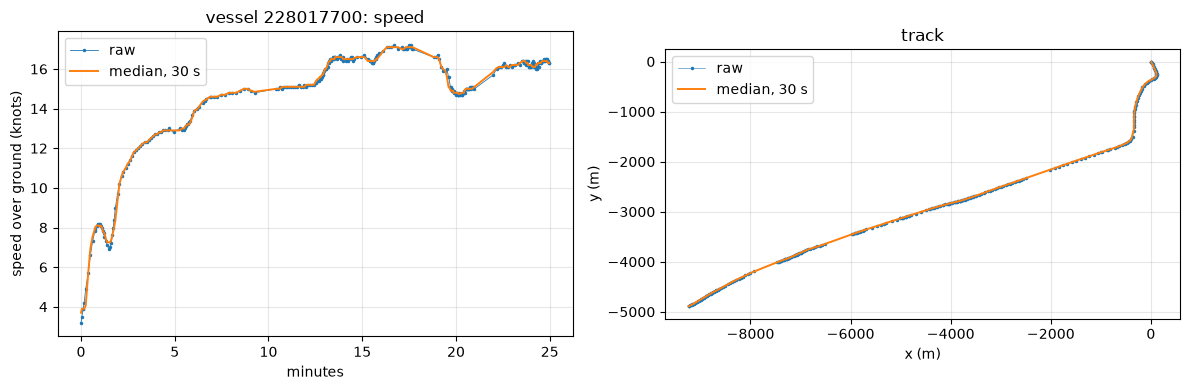

In [19]:
# one busy, moving vessel: 300 positions from where it starts to move
moving = before[before.speed_over_ground > 3].groupby("mmsi").size()
vessel = moving.idxmax()
first = before.index[(before.mmsi == vessel) & (before.speed_over_ground > 3)][0]      # where it starts to move
sel = before.index[before.mmsi == vessel]
sel = sel[sel >= first][:300]
b, a = before.loc[sel], ais.loc[sel]
minutes = (b.unix_time - b.unix_time.iloc[0]) / 60

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(minutes, b.speed_over_ground, ".-", ms=3, lw=.6, color="#1f77b4", label="raw")
axes[0].plot(minutes, a.speed_over_ground, "-", lw=1.4, color="#ff7f0e", label="median, 30 s")
axes[0].set(xlabel="minutes", ylabel="speed over ground (knots)", title=f"vessel {vessel}: speed")
axes[0].legend()
axes[1].plot(b.x - b.x.iloc[0], b.y - b.y.iloc[0], ".-", ms=3, lw=.4, color="#1f77b4", label="raw")
axes[1].plot(a.x - b.x.iloc[0], a.y - b.y.iloc[0], "-", lw=1.4, color="#ff7f0e", label="median, 30 s")
axes[1].set(xlabel="x (m)", ylabel="y (m)", title="track", aspect="equal")
axes[1].legend()
fig.tight_layout()
plt.show()

In [20]:
print(f"AIS after all steps: {len(ais):,} positions, {ais.mmsi.nunique()} vessels")
print(ais.dtypes.to_string())
display(ais.head(3))

AIS after all steps: 237,318 positions, 565 vessels
mmsi                     int64
navigational_status    float32
rate_of_turn           float32
speed_over_ground      float32
course_over_ground     float32
true_heading           float32
lon                    float64
lat                    float64
unix_time                int64
ship_type_code         float32
vessel_type                str
x                      float64
y                      float64


,mmsi,navigational_status,rate_of_turn,speed_over_ground,course_over_ground,true_heading,lon,lat,unix_time,ship_type_code,vessel_type,x,y
0,209211000,0.0,0.0,8.3,239.500000,237.0,-5.344962,49.039345,1447069696,79.0,Cargo,328625.405101,5.434479e+06
1,209211000,0.0,0.0,7.6,239.699997,237.0,-5.510897,48.976147,1447073296,79.0,Cargo,316267.073673,5.427842e+06
2,209211000,0.0,0.0,8.2,210.699997,216.0,-5.799622,48.835360,1447080495,79.0,Cargo,294565.368206,5.412934e+06


## 1.2 Weather

Hourly observations at 16 coastal stations (rp5.ua, from Met Office / NOAA data), in `table_wheatherObservation.csv`
(sic: the archive's file name has the typo), with the stations in `table_weatherStation.csv` and the wind-direction
codes in `table_windDirection.csv`.

### Step 14: read the three tables (`read_weather_raw`)

The observations keep the archive's column names (`T`, `Tn`, `P`, `U`, `Ff`, ...) until the stations are merged in step 16.

In [21]:
n0 = len(rep)
obs, stations, wind = read_weather_raw(RAW / "E2_Weather_Conditions", rep)
display(show(rep, n0))
display(obs.head(3))
display(stations.head(3))
print(len(stations), "stations;", len(wind), "wind direction codes")

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,read_weather_raw,rows read,768,768,0,0


,id_station,local_time,T,Tn,Tx,P,U,id_windDirection,Ff,ff10,ff3,VV,Td,RRR,tR
0,3803,1447196400,13.8,-65536.0,-65536.0,766.9,91,10,9,-65536,-65536,11.0,12.3,-65536.0,-65536
1,3803,1447192800,13.7,-65536.0,-65536.0,767.0,92,10,8,-65536,-65536,11.0,12.4,-65536.0,-65536
2,3803,1447189200,13.8,-65536.0,-65536.0,767.2,91,10,9,-65536,-65536,11.0,12.4,-65536.0,-65536


,id_station,station_name,latitude,longitude,elevation
0,7107,BRIGNOGAN,48.6833,-4.03330,20
1,7100,OUESSANT,48.4733,-5.05690,68
2,7117,PERROS GUIREC,48.8258,-3.47295,48


16 stations; 19 wind direction codes


### Step 15: the "missing" code -65536 becomes NaN (`weather_unavailable_to_nan`)

**What.** In every column the archive's code for "missing" is **-65536**: here it becomes NaN.

**Why.** -65536 is a number to a mean, a filter or a plot (it would be an air pressure of -65536 mm Hg). Most stations
do not report every field every hour (gusts, precipitation and the minimum and maximum temperature are mostly missing).

**Source.** `E2_Weather_Conditions/README_parameters.txt`.

In [22]:
n0 = len(rep)
cols = [c for c in obs.columns if c not in ("id_station", "local_time")]
count = (obs[cols] == -65536).sum()
obs = weather_unavailable_to_nan(obs, rep)
display(pd.DataFrame({"rows with -65536": count, "NaN after": obs[cols].isna().sum()}).T)
display(show(rep, n0).query("values_to_nan > 0"))

,T,Tn,Tx,P,U,id_windDirection,Ff,ff10,ff3,VV,Td,RRR,tR
rows with -65536,1,714,714,1,1,0,0,743,81,215,1,744,206
NaN after,1,714,714,1,1,0,0,743,81,215,1,744,206


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,weather_unavailable_to_nan,air_temperature == -65536,768,768,0,1
1,weather_unavailable_to_nan,min_air_temperature == -65536,768,768,0,714
2,weather_unavailable_to_nan,max_air_temperature == -65536,768,768,0,714
3,weather_unavailable_to_nan,air_pressure == -65536,768,768,0,1
4,weather_unavailable_to_nan,relative_humidity == -65536,768,768,0,1
7,weather_unavailable_to_nan,max_gust_10min == -65536,768,768,0,743
8,weather_unavailable_to_nan,max_gust == -65536,768,768,0,81
9,weather_unavailable_to_nan,visibility == -65536,768,768,0,215
10,weather_unavailable_to_nan,dew_point == -65536,768,768,0,1
11,weather_unavailable_to_nan,precipitation == -65536,768,768,0,744


### Step 16: add each station's position (`merge_weather_stations`)

**What.** The columns get descriptive names (`T` to `air_temperature`, `Ff` to `wind_speed`, `local_time` to
`unix_time`, ...) and each observation gets its station's `latitude` and `longitude`. An observation whose
station is not in the station table is dropped.

**Why.** The position is what lets an AIS point be matched to the nearest station later (notebook 02).
A station without a position cannot be used.

**Source.** `table_weatherStation.csv`, `README_parameters.txt` for the names and units.

In [23]:
n0 = len(rep)
obs = merge_weather_stations(obs, stations, rep)
display(show(rep, n0))
display(obs.head(3))
print(list(obs.columns))

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,merge_weather_stations,station in station table,768,768,0,0


,station_id,unix_time,air_temperature,min_air_temperature,max_air_temperature,air_pressure,relative_humidity,wind_direction_code,wind_speed,max_gust_10min,max_gust,visibility,dew_point,precipitation,precipitation_period,latitude,longitude
0,3803,1447196400,13.8,NaN,NaN,766.9,91.0,10,9,NaN,NaN,11.0,12.3,NaN,NaN,49.9167,-6.3
1,3803,1447192800,13.7,NaN,NaN,767.0,92.0,10,8,NaN,NaN,11.0,12.4,NaN,NaN,49.9167,-6.3
2,3803,1447189200,13.8,NaN,NaN,767.2,91.0,10,9,NaN,NaN,11.0,12.4,NaN,NaN,49.9167,-6.3


['station_id', 'unix_time', 'air_temperature', 'min_air_temperature', 'max_air_temperature', 'air_pressure', 'relative_humidity', 'wind_direction_code', 'wind_speed', 'max_gust_10min', 'max_gust', 'visibility', 'dew_point', 'precipitation', 'precipitation_period', 'latitude', 'longitude']


### Step 17: time inside the period, January out (`drop_invalid_weather`, `drop_excluded_periods`)

The same two rules as for AIS (steps 4 and 5) on the weather's `unix_time`: inside 2015-10-01 to 2016-03-31, and
not in January 2016 (the weather of that month is left out so that all datasets cover the same period).

In [24]:
n0 = len(rep)
obs = drop_invalid_weather(obs, rep)
obs = drop_excluded_periods(obs, EXCLUDED_PERIODS, rep, dataset="weather")
display(show(rep, n0))
print("times:", when(obs.unix_time.min()), "to", when(obs.unix_time.max()))

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_invalid_time,unix_time inside the archive period,768,768,0,0
1,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),768,768,0,0


times: 2015-11-09 00:00:00 to 2015-11-10 23:00:00


### Step 18: physical ranges (`check_weather_ranges`)

**What.** A value outside its range becomes NaN. The README gives units but no limits, so the limits are physical ones, wide enough to hold every
real observation (world records, in the README's units):

| field | range |
|---|---|
| air, minimum, maximum temperature, dew point | -90 to 60 degrees C |
| `air_pressure` | 640 to 820 mm of mercury (870 to 1085 hPa is the record range) |
| `relative_humidity` | 0 to 100 % |
| `wind_speed`, the two gusts | 0 to 120 m/s |
| `visibility` | 0 to 100 km |
| `precipitation` | 0 to 1000 mm; its period 0 to 24 hours |
| `wind_direction_code` | must be in `table_windDirection.csv` |

**Why.** To catch decoding and transcription errors (a pressure of 2000, a humidity of 150) without
discarding real extremes. **Source.** World records; the units are the README's.

The sample's data are clean, so a made-up table shows the rule.

In [25]:
demo = pd.DataFrame({"air_temperature": [12.0, 95.0], "air_pressure": [765.0, 2000.0], "relative_humidity": [80.0, 150.0],
                     "wind_speed": [5.0, 130.0], "visibility": [10.0, -3.0], "wind_direction_code": [10, 99]})
demo_rep = PreprocessingReport()
out = check_weather_ranges(demo, wind, demo_rep)
print("made-up values, before and after (the second row is all wrong):")
display(demo)
display(out)

n0 = len(rep)
obs = check_weather_ranges(obs, wind, rep)
print("the sample:")
display(show(rep, n0))
num = [c for c in obs.columns if c in A.WEATHER_FILTERED or c == "precipitation_period"]
display(obs[num].describe().loc[["count", "min", "max"]].round(1))

made-up values, before and after (the second row is all wrong):


,air_temperature,air_pressure,relative_humidity,wind_speed,visibility,wind_direction_code
0,12.0,765.0,80.0,5.0,10.0,10
1,95.0,2000.0,150.0,130.0,-3.0,99


,air_temperature,air_pressure,relative_humidity,wind_speed,visibility,wind_direction_code
0,12.0,765.0,80.0,5.0,10.0,10.0
1,NaN,NaN,NaN,NaN,NaN,NaN


the sample:


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,check_weather_ranges,air_temperature outside -90..60,768,768,0,0
1,check_weather_ranges,min_air_temperature outside -90..60,768,768,0,0
2,check_weather_ranges,max_air_temperature outside -90..60,768,768,0,0
3,check_weather_ranges,dew_point outside -90..60,768,768,0,0
4,check_weather_ranges,air_pressure outside 640..820,768,768,0,0
5,check_weather_ranges,relative_humidity outside 0..100,768,768,0,0
6,check_weather_ranges,wind_speed outside 0..120,768,768,0,0
7,check_weather_ranges,max_gust_10min outside 0..120,768,768,0,0
8,check_weather_ranges,max_gust outside 0..120,768,768,0,0
9,check_weather_ranges,visibility outside 0..100,768,768,0,0


,air_temperature,min_air_temperature,max_air_temperature,air_pressure,relative_humidity,wind_speed,max_gust_10min,max_gust,visibility,dew_point,precipitation,precipitation_period
count,767.0,54.0,54.0,767.0,767.0,768.0,25.0,687.0,553.0,767.0,24.0,562.0
min,8.8,9.0,12.8,765.4,57.0,0.0,13.0,2.0,0.3,6.8,0.2,1.0
max,19.6,15.1,20.5,775.6,100.0,16.0,23.0,23.0,60.0,15.8,2.0,12.0


### Step 19: project the stations, sort and filter (`denoise_weather`)

**What.** `x` and `y` (EPSG:32630) are added from the station positions, the table is sorted by (station, time) and
the numeric measurements are median-filtered per station with the same 30 s window as the AIS.

**Why.** The same filter keeps one definition of the cleaning step for every dataset; the stations' `x`, `y` are in
the CRS of the AIS positions. With hourly observations a 30 s window holds a single observation, so **the
weather values do not change**: the cell checks this.

**Source.** `catraj.preprocessing.filtering`.

In [26]:
n0, before = len(rep), obs.sort_values(["station_id", "unix_time"], kind="stable").reset_index(drop=True)
obs = denoise_weather(obs, 30, rep)
display(show(rep, n0))
cols = [c for c in A.WEATHER_FILTERED]
same = np.isclose(obs[cols].to_numpy(dtype=float), before[cols].to_numpy(dtype=float), equal_nan=True)
print("measurements unchanged by the filter:", bool(same.all()), f"({same.size:,} values compared)")
display(obs[["station_id", "unix_time", "air_temperature", "wind_speed", "x", "y"]].head(3))
print(f"{len(obs)} rows = {obs.station_id.nunique()} stations x {len(obs) // obs.station_id.nunique()} hours")

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,denoise_weather,"median filter, 30 s window",768,768,0,0


measurements unchanged by the filter: True (8,448 values compared)


,station_id,unix_time,air_temperature,wind_speed,x,y
0,3803,1447027200,12.3,8.0,263112.557063,5.534591e+06
1,3803,1447030800,12.3,9.0,263112.557063,5.534591e+06
2,3803,1447034400,12.4,10.0,263112.557063,5.534591e+06


768 rows = 16 stations x 48 hours


## 1.3 Ocean (sea state)

`oc_<month>.csv` holds a WAVEWATCH III forecast (SHOM-IFREMER) on a grid of about 0.033 degrees, every 3 hours:
water depth, sea level, significant wave height, wave length and wave direction.

### Step 20: read the file with descriptive names (`read_ocean_raw`)

`dpt` becomes `bottom_depth`, `wlv` `sea_level`, `hs` `wave_height`, `lm` `wave_length`, `dir` `wave_direction`
and `ts` `unix_time`.

In [27]:
n0 = len(rep)
oc = read_ocean_raw(RAW / "E1_ocean" / "oc_november.csv", rep)
display(show(rep, n0))
display(oc.head(3))
print(f"{oc[['lon', 'lat']].drop_duplicates().shape[0]:,} grid cells x {oc.unix_time.nunique()} time steps")

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,read_ocean_raw,rows read,850860,850860,0,0


,lon,lat,bottom_depth,sea_level,wave_height,wave_length,wave_direction,unix_time
0,-9.6333,45.0,4804.0,0.0,2.176,120,262.1,1447023600
1,-9.6000,45.0,4817.0,0.0,2.172,120,262.1,1447023600
2,-9.5667,45.0,4829.5,0.0,2.168,120,262.1,1447023600


47,270 grid cells x 18 time steps


### Step 21: does the file belong to its month? (`ocean_month_matches`)

**What.** The month of a file is checked against its times (the median time must fall in the month of the file
name). A file whose times are not in its month is **skipped**, not written under the wrong name.

**Why.** The archive's `oc_january.csv` is a byte-for-byte copy of `oc_november.csv`: there is no sea state for
January 2016. Without this check the November data would be saved as January and used for January's ships. (Together
with the January exclusion of step 5, no January data enters the preprocessed archive.)

**Source.** The archive's files; the MD5 of the zip is the one Zenodo publishes. If the full archive is downloaded
the cell compares the two files byte by byte.

In [28]:
print("median time of the sample's file:", when(oc.unix_time.median()))
for month in ("november", "january", "december"):
    print(f"  is it oc_{month}.csv?", ocean_month_matches(oc, month))

jan, nov = FULL_RAW / "E1_ocean" / "oc_january.csv", FULL_RAW / "E1_ocean" / "oc_november.csv"
if jan.exists() and nov.exists():
    def md5(path):
        h = hashlib.md5()
        with open(path, "rb") as f:
            while chunk := f.read(16 << 20):
                h.update(chunk)
        return h.hexdigest()
    print("\nfull archive:  md5 of oc_november.csv", md5(nov), "\n               md5 of oc_january.csv ", md5(jan))
else:
    print("\n(the full archive is not downloaded here: Part 2; its oc_january.csv is identical to oc_november.csv)")

median time of the sample's file: 2015-11-10 00:30:00
  is it oc_november.csv? True
  is it oc_january.csv? False
  is it oc_december.csv? False



full archive:  md5 of oc_november.csv 1aefa2388cd2ec31fd482b335a67cbcf 
               md5 of oc_january.csv  1aefa2388cd2ec31fd482b335a67cbcf


### Step 22: inside the area and the period; January out (`drop_invalid_ocean`, `drop_excluded_periods`)

Rows whose time is outside the archive's period, or whose cell is outside the archive's area, are dropped; the
January exclusion is applied to the sea-state rows as well. The sample was cut to the area, so nothing goes.

In [29]:
n0 = len(rep)
oc = drop_invalid_ocean(oc, AREA, rep)
oc = drop_excluded_periods(oc, EXCLUDED_PERIODS, rep, dataset="ocean")
display(show(rep, n0))

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_invalid_time,unix_time inside the archive period,850860,850860,0,0
1,drop_invalid_ocean,cell inside archive area,850860,850860,0,0
2,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),850860,850860,0,0


### Step 23: land cells (`drop_land_cells`)

**What.** A cell whose `bottom_depth` is -16000 or less is land (the undefined depth is -16384): its rows are
dropped.

**Why.** The model has no sea state on land: **all the other fields of those rows are undefined** (the codes
below). Keeping them would mean thousands of rows of nothing. A cell never changes its depth, so a land cell is land at
every time step.

**Source.** `E1_ocean/README_parameters.txt` (undefined depth -16384).

The cell counts the undefined codes in the land rows and in the sea rows before dropping, and maps the cells.

,bottom_depth,sea_level,wave_height,wave_length,wave_direction
in land rows,0,173124,173124,173124,172944
in sea rows,0,0,0,75,65


173,124 of 850,860 rows are land (20.3%)


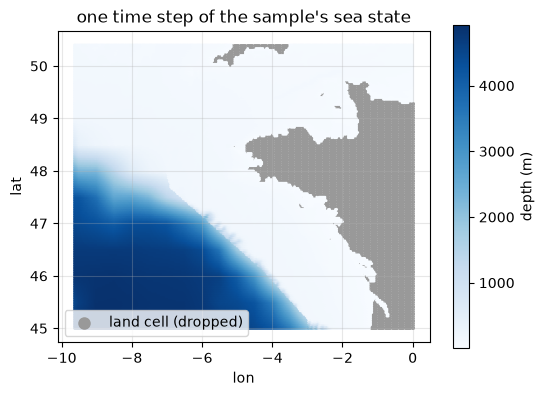

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,drop_land_cells,bottom_depth > -16000 (sea cell),850860,677736,173124,0


In [30]:
land = oc.bottom_depth <= -16000
codes = {"bottom_depth": -16384, "sea_level": -327.67, "wave_height": -65.534, "wave_length": -32767, "wave_direction": -3276.7}
display(pd.DataFrame({c: {"in land rows": int(np.isclose(oc.loc[land, c], v).sum()),
                         "in sea rows": int(np.isclose(oc.loc[~land, c], v).sum())} for c, v in codes.items()}))
print(f"{int(land.sum()):,} of {len(oc):,} rows are land ({land.mean():.1%})")

first = oc[oc.unix_time == oc.unix_time.min()]
fig, ax = plt.subplots(figsize=(6, 6))
sea = first.bottom_depth > -16000
ax.scatter(first.lon[~sea], first.lat[~sea], s=1, c="#999999", rasterized=True, label="land cell (dropped)")
sc = ax.scatter(first.lon[sea], first.lat[sea], s=1, c=first.bottom_depth[sea], cmap="Blues", rasterized=True)
fig.colorbar(sc, label="depth (m)", shrink=.7)
ax.set(xlabel="lon", ylabel="lat", title="one time step of the sample's sea state", aspect=1 / np.cos(np.radians(48)))
ax.legend(markerscale=8, loc="lower left")
plt.show()

n0 = len(rep)
oc = drop_land_cells(oc, rep)
display(show(rep, n0))

### Step 24: undefined values become NaN (`ocean_unavailable_to_nan`)

**What.** From the README, the codes for "undefined" are: depth -16384 (handled by step 23), sea level
-327.67, wave height -65.534, wave length -32767, wave direction -3276.7. A negative wave height, length or direction,
and a sea level of -327 or less, become NaN.

**Why.** A negative height or length is not physical. The sea level may be negative (a tide), so only its code,
-327.67, is undefined: that is why the rule is "-327 or less" and not "below zero".

**Source.** `E1_ocean/README_parameters.txt`.

On the sea cells that remain, only a few wave lengths and directions are undefined (the counts below): all the other
codes belonged to land rows.

In [31]:
n0 = len(rep)
oc = ocean_unavailable_to_nan(oc, rep)
display(show(rep, n0))
print(oc[["sea_level", "wave_height", "wave_length", "wave_direction"]].isna().sum().to_string())

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,ocean_unavailable_to_nan,wave_height < 0 (undefined),677736,677736,0,0
1,ocean_unavailable_to_nan,wave_length < 0 (undefined),677736,677736,0,75
2,ocean_unavailable_to_nan,wave_direction < 0 (undefined),677736,677736,0,65
3,ocean_unavailable_to_nan,sea_level <= -327 (undefined),677736,677736,0,0


sea_level          0
wave_height        0
wave_length       75
wave_direction    65


### Step 25: physical ranges (`check_ocean_ranges`)

**What.** A value outside its range becomes NaN: depth at most 11000 m (the deepest ocean), sea level -20 to 20 m,
wave height 0 to 30 m, wave length 0 to 2000 m, wave direction 0 <= v < 360 degrees.

**Why.** To catch errors without discarding real extremes (the largest waves measured are about 30 m).
**Source.** World records, in the README's units.

In [32]:
n0 = len(rep)
oc = check_ocean_ranges(oc, rep)
display(show(rep, n0))
display(oc[["bottom_depth", "sea_level", "wave_height", "wave_length", "wave_direction"]].describe().loc[["count", "min", "max"]].round(2))

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,check_ocean_ranges,bottom_depth > 11000,677736,677736,0,0
1,check_ocean_ranges,sea_level outside -20..20,677736,677736,0,0
2,check_ocean_ranges,wave_height outside 0..30,677736,677736,0,0
3,check_ocean_ranges,wave_length outside 0..2000,677736,677736,0,0
4,check_ocean_ranges,wave_direction outside 0..<360,677736,677736,0,0


,bottom_depth,sea_level,wave_height,wave_length,wave_direction
count,677736.0,677736.00,677736.00,677661.0,677671.0
min,0.5,-2.18,0.00,4.0,0.3
max,4923.0,3.03,5.57,227.0,359.8


### Step 26: sort by grid point and time (`sort_ocean`), step 27: median filter (`denoise_ocean`)

`sort_ocean` sorts by `(lon, lat, unix_time)` so that each grid point's series is contiguous.
`denoise_ocean` then filters each grid point's series (sea level, wave height, length, and direction on the circle) with
the same 30 s median. The forecast is three-hourly, so a window holds one value and **the series do not change**; the
step exists so every dataset goes through the same definition (and so that a different `window` works for all).

In [33]:
n0 = len(rep)
oc = sort_ocean(oc, rep)
before = oc.copy()
oc = denoise_ocean(oc, 30, rep)
display(show(rep, n0))
cols = ["sea_level", "wave_height", "wave_length", "wave_direction"]
print("values unchanged by the filter:", bool(np.isclose(oc[cols].to_numpy(dtype=float), before[cols].to_numpy(dtype=float), equal_nan=True).all()))
display(oc.head(3))

,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,sort_ocean,"sorted by (lon, lat, unix_time)",677736,677736,0,0
1,denoise_ocean,"median filter, 30 s window",677736,677736,0,0


values unchanged by the filter: True


,lon,lat,bottom_depth,sea_level,wave_height,wave_length,wave_direction,unix_time
0,-9.6333,45.0,4804.0,0.0,2.176,120.0,262.1,1447023600
1,-9.6333,45.0,4804.0,0.0,2.180,126.0,267.4,1447034400
2,-9.6333,45.0,4804.0,0.0,2.170,127.0,271.2,1447045200


## 1.4 Coastline

`C2_European_Coastline` is the EEA's polygons of European land ("EEA coastline for analysis"), in EPSG:3035.

### Steps 28 to 30: read, project, clip (`read_coastline`, `project_coastline`, `clip_coastline`)

**What.** (28) The polygons that touch the archive's area are read. (29) They are reprojected from EPSG:3035 to
**EPSG:32630**, the CRS of the AIS positions. (30) They are clipped to the area's outline (a rectangle in
longitude and latitude, densified so its edges curve in UTM), and empty results are dropped.

**Why.** The positions and the land must be in one CRS to ask "is this point on land?" (notebook 03/04, the
topology-preserving compression). The coastline of all Europe is large; only the area is kept.

**Source.** EEA (acknowledge the source: Copyright holder DG ENV, http://www.eea.europa.eu/legal/copyright).

as read: CRS EPSG:3035 | polygons: 729
projected: CRS EPSG:32630


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,read_coastline,polygons touching the area,729,729,0,0
1,project_coastline,to EPSG:32630,729,729,0,0
2,clip_coastline,clipped to the area,729,729,0,0


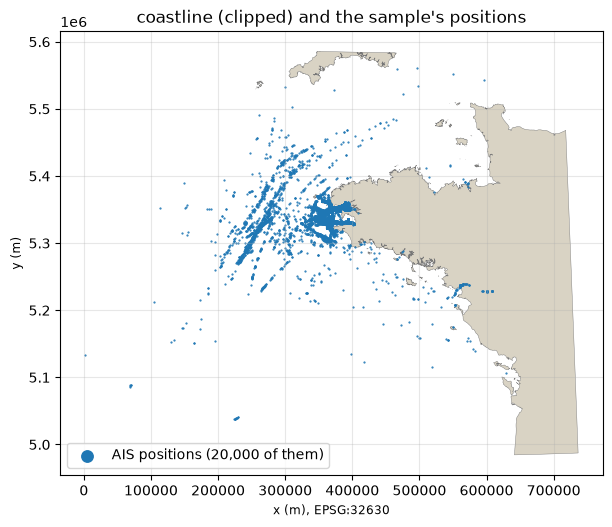

In [34]:
shp = RAW / "C2_European_Coastline" / "Europe Coastline (Polygone).shp"
n0 = len(rep)
coast = read_coastline(shp, AREA, rep)
print("as read: CRS", coast.crs.to_string(), "| polygons:", len(coast))
coast = project_coastline(coast, 32630, rep)
print("projected: CRS", coast.crs.to_string())
coast = clip_coastline(coast, AREA, rep)
display(show(rep, n0))

fig, ax = plt.subplots(figsize=(7, 6))
coast.plot(ax=ax, color="#d9d3c4", edgecolor="#777777", linewidth=.3)
pick = ais.sample(min(len(ais), 20000), random_state=0)
ax.scatter(pick.x, pick.y, s=.3, c="#1f77b4", rasterized=True, label="AIS positions (20,000 of them)")
ax.set(xlabel="x (m), EPSG:32630", ylabel="y (m)", title="coastline (clipped) and the sample's positions")
ax.legend(markerscale=15, loc="lower left")
plt.show()

## 1.5 Write the result: `preprocess_archive`

`preprocess_archive` runs all of the steps above (with the same functions, in the same order) on every dataset it finds and writes the
files other notebooks read through `catraj.datasets`:

| file | content |
|---|---|
| `AIS/ais.parquet`, `AIS/mmsi_check.csv` | the clean positions with vessel type; the MMSI classes found |
| `Weather/weather.parquet` | hourly observations with station positions |
| `Ocean/ocean_november.parquet` | sea state on sea cells |
| `Coastline/coastline.parquet` | land polygons (GeoParquet, EPSG:32630) |
| `preprocessing_report.csv`, `.txt` | rows in and out and values set to NaN of every rule |

It writes to `data/sample/preprocessed/`, the **committed** folder, with `force=True`. The result is
deterministic, so running it again reproduces the committed files: the cell hashes every file before and after
and says whether anything changed (`git status data/sample/preprocessed` shows the same).

In [35]:
def digests(folder):
    return {p.relative_to(folder).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(folder.rglob("*")) if p.is_file()}

committed = digests(OUT)
t = time.perf_counter()
report = preprocess_archive(RAW, OUT, 30, force=True, n_jobs=N_JOBS)
print(f"\nwritten in {time.perf_counter() - t:.1f} s")
after = digests(OUT)
changed = [f for f in after if committed.get(f) != after[f]] + [f for f in committed if f not in after]
print("files that differ from the committed ones:", changed if changed else "none (reproduced byte for byte)")

skip ocean october: raw file absent (C:\dev\CATraj\data\sample\raw\E1_ocean\oc_october.csv)
skip ocean december: raw file absent (C:\dev\CATraj\data\sample\raw\E1_ocean\oc_december.csv)
skip ocean january: raw file absent (C:\dev\CATraj\data\sample\raw\E1_ocean\oc_january.csv)
skip ocean february: raw file absent (C:\dev\CATraj\data\sample\raw\E1_ocean\oc_february.csv)
skip ocean march: raw file absent (C:\dev\CATraj\data\sample\raw\E1_ocean\oc_march.csv)
weather ... (in parallel)
ocean november ... (in parallel)
coastline ... (in parallel)


  weather: 768 rows -> C:\dev\CATraj\data\sample\preprocessed\Weather\weather.parquet (0.6 s)
  ocean november: 677,736 rows -> C:\dev\CATraj\data\sample\preprocessed\Ocean\ocean_november.parquet (1.1 s)
  coastline: 729 rows -> C:\dev\CATraj\data\sample\preprocessed\Coastline\coastline.parquet (0.8 s)
AIS ... (16 processes)


  AIS: 237,318 rows -> C:\dev\CATraj\data\sample\preprocessed\AIS\ais.parquet (3.5 s)

written in 9.6 s
files that differ from the committed ones: none (reproduced byte for byte)


### The report

The report is the record of every rule: rows in, rows out, rows dropped, values set to NaN. It is written beside the
data as `preprocessing_report.csv` and `.txt`. The text below is what `preprocess_archive` wrote; the check after it compares
the written report with what the cells above recorded one step at a time.

In [36]:
print((OUT / "preprocessing_report.txt").read_text())
mine = rep.to_frame().reset_index(drop=True)
written = pd.read_csv(OUT / "preprocessing_report.csv")
cols = ["dataset", "step", "rows_in", "rows_out", "values_to_nan"]
print("\nthe step-by-step cells recorded the written report's rows in/out and NaN counts:",
      bool(len(mine) == len(written) and (mine[cols].values == written[cols].values).all()))

  dataset                       step                                                                        rule  rows_in  rows_out  rows_dropped  values_to_nan
      AIS               read_ais_raw                                                                   rows read   239075    239075             0              0
      AIS          drop_invalid_mmsi                                      mmsi: distress device (SART/MOB/EPIRB)        1         0             1              0
      AIS          drop_invalid_mmsi                                                           mmsi: placeholder        1         0             1              0
      AIS          drop_invalid_mmsi                                                     mmsi: ship station kept   239075    239073             2              0
      AIS          drop_invalid_time                                         unix_time inside the archive period   239073    239073             0              0
      AIS      drop_excluded_perio

In [37]:
# the step-by-step tables equal the written files
loaded = load_ais(OUT)
cols = [c for c in ais.columns]
pd.testing.assert_frame_equal(pd.DataFrame(loaded[cols]), ais[cols].reset_index(drop=True), check_dtype=False)
print("AIS: the cells' table equals ais.parquet:", len(loaded), "rows")
w = load_weather(OUT)
pd.testing.assert_frame_equal(pd.DataFrame(w[list(obs.columns)]), obs.reset_index(drop=True), check_dtype=False)
print("weather: equals weather.parquet:", len(w), "rows")
o = load_ocean(OUT)
pd.testing.assert_frame_equal(o[list(oc.columns)], oc.reset_index(drop=True), check_dtype=False)
print("ocean: equals ocean_november.parquet:", len(o), "rows")
c = load_coastline(OUT)
print("coastline:", len(c), "polygons, CRS", c.crs.to_epsg(), "| the cells' table:", len(coast), "polygons")

print()
for f, size in [(p.relative_to(OUT).as_posix(), p.stat().st_size) for p in sorted(OUT.rglob("*")) if p.is_file()]:
    print(f"{size / 1e6:8.2f} MB  {f}")

AIS: the cells' table equals ais.parquet: 237318 rows


weather: equals weather.parquet: 768 rows
ocean: equals ocean_november.parquet: 677736 rows
coastline: 729 polygons, CRS 32630 | the cells' table: 729 polygons

    6.98 MB  AIS/ais.parquet
    0.00 MB  AIS/mmsi_check.csv
    0.81 MB  Coastline/coastline.parquet
    1.94 MB  Ocean/ocean_november.parquet
    0.01 MB  preprocessing_report.csv
    0.01 MB  preprocessing_report.txt
    0.02 MB  Weather/weather.parquet


# Part 2 · Download the full archive, file by file

The sample is a two-day cut. The full archive is on Zenodo: <https://zenodo.org/records/1167595>
(Ray et al., 2019, *Heterogeneous integrated dataset for Maritime Intelligence, Surveillance, and Reconnaissance*,
Data in Brief 25, 104141; data doi:10.5281/zenodo.1167595).

**What is downloaded, and how large.** Five zip files, 825 MB in all. The cell below lists them with the sizes. They are
extracted into `data/zenodo_1167595/`: about 5.3 GB of CSV, 4 GB of it the six months of sea state (each `oc_<month>.csv` is
about 0.67 GB). **How long it takes** depends on your connection: at 10 MB/s, about 1.5 minutes; at 1 MB/s, about 15 minutes.
Preprocessing (Part 3) takes about 2 minutes more.

**How.** `DOWNLOAD = True` (below) makes the cell call `scripts/download_data.py`: the notebook imports it and uses its
functions instead of repeating its logic. For each file, one at a time:

* it streams the file with a progress line (MB done / total, MB/s). An interrupted download **resumes** where it stopped
  (a `.part` file and an HTTP range request) and is retried up to five times;
* it checks the **MD5** against the checksum published on the record (a corrupted zip is deleted and must be downloaded again);
* it extracts the files the code reads into `data/zenodo_1167595/<folder>/`.

**Never overwritten.** A file already in place is skipped ("already in place"): nothing is deleted or downloaded again, and the zips
are kept (`remove_zip=False`; the script's `--remove-zips` would delete them).

**Licences** (details in `data/LICENSE.md`): the AIS data is **CC BY-NC-SA 4.0** (attribute NARI, Brest; no commercial use; derived
data under the same licence); the sea state (SHOM-IFREMER, WAVEWATCH III) is public with the citation mandatory (Boudiere et al., 2013,
doi:10.1016/j.ijome.2013.11.010); the weather (rp5.ua, from Met Office / NOAA data) is public, cite the source; the European coastline
(EEA) may be re-used free of charge when the source is acknowledged. The code's BSD licence does not cover the data.

The same can be done in a terminal: `python scripts/download_data.py` (and `--check` for the report).

In [38]:
import importlib.util

spec = importlib.util.spec_from_file_location("download_data", ROOT / "scripts" / "download_data.py")
dd = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dd)                 # the script's functions; nothing is run

MONTHS = list(dd.MONTHS)                    # oct, nov, dec, jan, feb, mar: every sea-state month (Part 3 skips January)
NAMES = dd.TARGETS["all"]

table = pd.DataFrame([{"zenodo file": n, "size (MB)": dd.ARCHIVES[n]["size"] / 1e6, "extracted to": dd.ARCHIVES[n]["folder"] + "/",
                       "in place": dd.present(n, MONTHS)} for n in NAMES])
display(table.round(3))
print(f"total download: {table['size (MB)'].sum():,.0f} MB; missing now: "
      f"{table.loc[~table['in place'], 'size (MB)'].sum():,.0f} MB")

,zenodo file,size (MB),extracted to,in place
0,[P1] AIS Data.zip,201.434,P1_AIS_Data/,True
1,"[P1] AIS Status, Codes and Types.zip",0.008,P1_AIS_Codes/,True
2,[E2] Weather Conditions.zip,1.347,E2_Weather_Conditions/,True
3,[E1] Ocean Conditions.zip,569.846,E1_ocean/,True
4,[C2] European Coastline.zip,52.614,C2_European_Coastline/,True


total download: 825 MB; missing now: 0 MB


In [39]:
if DOWNLOAD:
    dd.DATA.mkdir(parents=True, exist_ok=True)
    for name in NAMES:                      # one file at a time; download_data.fetch prints its progress
        t = time.perf_counter()
        dd.fetch(name, MONTHS, remove_zip=False)
        print(f"  {time.perf_counter() - t:.1f} s")
else:
    print("DOWNLOAD is False: nothing is downloaded. Set DOWNLOAD = True in the settings cell to fetch what is missing.")

DOWNLOAD is False: nothing is downloaded. Set DOWNLOAD = True in the settings cell to fetch what is missing.


### What is present (the `--check` report)

`dd.report` is what `python scripts/download_data.py --check` prints: one line per Zenodo file, marked when everything the code reads from it is
extracted. The second table lists the sea-state months.

In [40]:
print(f"data for 'all' in {dd.DATA.relative_to(dd.ROOT).as_posix()}/ (every sea-state month):")
complete = dd.report(NAMES, MONTHS)
print("\ncomplete:", complete)
print("\nsea-state files:")
for m, full in dd.MONTHS.items():
    f = dd.DATA / "E1_ocean" / f"oc_{full}.csv"
    print(f"  [{'x' if f.exists() else ' '}] oc_{full}.csv" + (f"   {f.stat().st_size / 1e6:,.0f} MB" if f.exists() else ""))

data for 'all' in data/zenodo_1167595/ (every sea-state month):
  [x] [P1] AIS Data.zip                        data/zenodo_1167595/P1_AIS_Data/
  [x] [P1] AIS Status, Codes and Types.zip     data/zenodo_1167595/P1_AIS_Codes/
  [x] [E2] Weather Conditions.zip              data/zenodo_1167595/E2_Weather_Conditions/
  [x] [E1] Ocean Conditions.zip                data/zenodo_1167595/E1_ocean/
  [x] [C2] European Coastline.zip              data/zenodo_1167595/C2_European_Coastline/

complete: True

sea-state files:
  [x] oc_october.csv   716 MB
  [x] oc_november.csv   698 MB
  [x] oc_december.csv   720 MB
  [x] oc_january.csv   698 MB
  [x] oc_february.csv   675 MB
  [x] oc_march.csv   720 MB


# Part 3 · Preprocess the full archive

`preprocess_archive(data/zenodo_1167595, data/zenodo_1167595/preprocessed)` runs, on every dataset it finds, the
steps of Part 1 in the same order (it is the very code the cells above called one by one). It writes the same files: `AIS/ais.parquet`,
`Weather/weather.parquet`, one `Ocean/ocean_<month>.parquet` per month and `Coastline/coastline.parquet`, plus the report. Months are skipped when
their raw file is absent, and **January 2016 is excluded** (its AIS and weather rows are dropped and its `oc_january.csv`, a copy of November, is
skipped). A dataset whose output exists is skipped unless `FORCE_FULL = True`.

* **How long.** About **2 minutes** for the whole archive (19 million AIS messages): 97 to 151 s serially and 82 to 89 s on 16 cores in the
  measurements of "Parallel processing", where it is also explained what runs in parallel. `PREPROCESS_FULL = True` runs it; the same can be done in a terminal:
  `python scripts/prepare_zenodo.py --n-jobs -1`.
* **When the flag is off** (the committed state), the cell loads the report of an existing full run and shows it, so the numbers below are those of the full
  archive. If no full output exists here, it says so.

The raw files are only read; the output goes to `data/zenodo_1167595/preprocessed/` (not committed).

In [41]:
if PREPROCESS_FULL:
    if not (FULL_RAW / "P1_AIS_Data" / "nari_dynamic.csv").exists():
        raise SystemExit("the full archive is not downloaded: set DOWNLOAD = True (Part 2) first")
    t = time.perf_counter()
    preprocess_archive(FULL_RAW, FULL_OUT, 30, force=FORCE_FULL, n_jobs=N_JOBS)
    print(f"preprocessed in {time.perf_counter() - t:.0f} s (n_jobs={N_JOBS})")
else:
    print("PREPROCESS_FULL is False: nothing is run here.")

full_report_path = FULL_OUT / "preprocessing_report.csv"
if full_report_path.exists():
    full = pd.read_csv(full_report_path)
    stamp = pd.Timestamp(full_report_path.stat().st_mtime, unit="s", tz="UTC").strftime("%Y-%m-%d %H:%M UTC")
    print(f"\nloaded the report of the full archive ({stamp}): {len(full)} lines")
else:
    full = None
    print("\nno full-archive output here (", FULL_OUT, "): run Parts 2 and 3 with the flags on.")

PREPROCESS_FULL is False: nothing is run here.

loaded the report of the full archive (2026-11-25 14:52 UTC): 142 lines


### The full report

One line per rule (the dataset, the step, the rule, the rows in and out, the rows dropped and the values set to NaN): the same record as for the
sample, now on 19 million messages. It is a long table, so the cell shows the AIS and the other datasets' lines apart.

In [42]:
if full is not None:
    cols = ["step", "rule", "rows_in", "rows_out", "rows_dropped", "values_to_nan"]
    fmt = {c: "{:,}".format for c in ["rows_in", "rows_out", "rows_dropped", "values_to_nan"]}
    pd.set_option("display.max_rows", 200)
    print("AIS")
    display(full[full.dataset == "AIS"][cols].reset_index(drop=True))

AIS


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,read_ais_raw,rows read,19035630,19035630,0,0
1,drop_invalid_mmsi,mmsi: placeholder,373926,0,373926,0
2,drop_invalid_mmsi,mmsi: group of ships,3507,0,3507,0
3,drop_invalid_mmsi,mmsi: craft of a parent ship,311,0,311,0
4,drop_invalid_mmsi,"mmsi: ship, unallocated MID",50,0,50,0
5,drop_invalid_mmsi,mmsi: distress device (SART/MOB/EPIRB),23,0,23,0
6,drop_invalid_mmsi,"mmsi: coast station, unallocated MID",5,0,5,0
7,drop_invalid_mmsi,mmsi: ship station kept,19035630,18657808,377822,0
8,drop_invalid_time,unix_time inside the archive period,18657808,18650803,7005,0
9,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),18650803,15439619,3211184,0


In [43]:
if full is not None:
    print("weather")
    display(full[full.dataset == "weather"][cols].reset_index(drop=True))

weather


,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,read_weather_raw,rows read,71515,71515,0,0
1,weather_unavailable_to_nan,air_temperature == -65536,71515,71515,0,105
2,weather_unavailable_to_nan,min_air_temperature == -65536,71515,71515,0,66486
3,weather_unavailable_to_nan,max_air_temperature == -65536,71515,71515,0,66477
4,weather_unavailable_to_nan,air_pressure == -65536,71515,71515,0,152
5,weather_unavailable_to_nan,relative_humidity == -65536,71515,71515,0,110
6,weather_unavailable_to_nan,wind_direction_code == -65536,71515,71515,0,0
7,weather_unavailable_to_nan,wind_speed == -65536,71515,71515,0,222
8,weather_unavailable_to_nan,max_gust_10min == -65536,71515,71515,0,64071
9,weather_unavailable_to_nan,max_gust == -65536,71515,71515,0,14051


In [44]:
if full is not None:
    print("ocean and coastline")
    display(full[full.dataset.isin(["ocean", "coastline"])][["dataset"] + cols].reset_index(drop=True))

ocean and coastline


,dataset,step,rule,rows_in,rows_out,rows_dropped,values_to_nan
0,ocean,read_ocean_raw,rows read,13511288,13511288,0,0
1,ocean,drop_invalid_time,unix_time inside the archive period,13511288,13456807,54481,0
2,ocean,drop_invalid_ocean,cell inside archive area,13456807,13456807,0,0
3,ocean,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),13456807,13456807,0,0
4,ocean,drop_land_cells,bottom_depth > -16000 (sea cell),13456807,10671882,2784925,0
5,ocean,ocean_unavailable_to_nan,wave_height < 0 (undefined),10671882,10671882,0,0
6,ocean,ocean_unavailable_to_nan,wave_length < 0 (undefined),10671882,10671882,0,101
7,ocean,ocean_unavailable_to_nan,wave_direction < 0 (undefined),10671882,10671882,0,93
8,ocean,ocean_unavailable_to_nan,sea_level <= -327 (undefined),10671882,10671882,0,0
9,ocean,check_ocean_ranges,bottom_depth > 11000,10671882,10671882,0,0


### Summary per dataset and month

The AIS rows and vessels per month are counted from the written `ais.parquet` (the `mmsi` and `unix_time` columns only, so it is fast);
weather and sea-state rows per month likewise. **January 2016 has no rows: it is excluded.**

In [45]:
if full is not None and (FULL_OUT / "AIS" / "ais.parquet").exists():
    def by_month(df, label):
        month = pd.to_datetime(df["unix_time"], unit="s", utc=True).dt.strftime("%Y-%m")
        return df.groupby(month)

    ais_t = pd.read_parquet(FULL_OUT / "AIS" / "ais.parquet", columns=["mmsi", "unix_time"])
    g = by_month(ais_t, "AIS")
    summary = pd.DataFrame({"AIS rows": g.size(), "vessels": g["mmsi"].nunique()})
    wx = pd.read_parquet(FULL_OUT / "Weather" / "weather.parquet", columns=["station_id", "unix_time"])
    summary["weather rows"] = by_month(wx, "weather").size()
    oc_rows = {}
    for f in sorted((FULL_OUT / "Ocean").glob("ocean_*.parquet")):
        o = pd.read_parquet(f, columns=["unix_time"])
        for k, v in by_month(o, "ocean").size().items():
            oc_rows[k] = oc_rows.get(k, 0) + int(v)
    summary["sea-state rows"] = pd.Series(oc_rows)
    summary = summary.reindex(["2015-10", "2015-11", "2015-12", "2016-01", "2016-02", "2016-03"]).fillna(0).astype(int)
    summary.index.name = "month"
    total = pd.DataFrame({"AIS rows": [len(ais_t)], "vessels": [ais_t.mmsi.nunique()], "weather rows": [len(wx)],
                          "sea-state rows": [sum(oc_rows.values())]}, index=["all months"])
    display(pd.concat([summary, total]).map("{:,}".format))
    del ais_t, wx
else:
    print("no full-archive output to summarise")

,AIS rows,vessels,weather rows,sea-state rows
2015-10,"3,087,931","1,930","11,787","10,715,088"
2015-11,"3,171,529","1,863","11,483","10,369,440"
2015-12,"2,579,690","1,948","11,782","10,628,676"
2016-01,0,0,0,0
2016-02,"3,136,159","1,130","11,100","10,023,792"
2016-03,"2,931,226","1,256","11,757","10,671,882"
all months,"14,906,535","4,720","57,909","52,408,878"


### The January exclusion, in numbers

What the report says about January: the rows each dataset lost to the exclusion rule, and the sea-state file that was skipped. The sea-state
lines are one per month file, in the order of the months; the skipped file shows as `ocean_month_matches`, with all the rows of its
November copy dropped (its `rows_in` equals November's).

In [46]:
if full is not None:
    jan = full[full.step.eq("drop_excluded_periods") | full.step.eq("ocean_month_matches")]
    display(jan[["dataset", "step", "rule", "rows_in", "rows_out", "rows_dropped"]].reset_index(drop=True))
    lost = jan[jan.step.eq("drop_excluded_periods")].groupby("dataset").rows_dropped.sum()
    print(f"January 2016 removed: {int(lost.get('AIS', 0)):,} AIS rows, {int(lost.get('weather', 0)):,} weather rows, "
          f"{int(lost.get('ocean', 0)):,} sea-state rows (the edge of a neighbouring month's file); "
          "the sea-state file oc_january.csv is a copy of November and is skipped as a whole.")
    mm = full[full.step.eq("drop_invalid_mmsi")][["rule", "rows_in", "rows_out", "rows_dropped"]]
    print("\nMMSI classes dropped from the full archive:")
    display(mm.reset_index(drop=True))

,dataset,step,rule,rows_in,rows_out,rows_dropped
0,AIS,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),18650803,15439619,3211184
1,weather,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),69776,57909,11867
2,ocean,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),13456807,13456807,0
3,ocean,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),13075440,13075440,0
4,ocean,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),13456807,13456807,0
5,ocean,ocean_month_matches,"oc_january.csv: times not in january, file skipped",13075440,0,13075440
6,ocean,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),12639592,12585111,54481
7,ocean,drop_excluded_periods,January 2016: no sea state in the archive (oc_january.csv repeats November),13511288,13511288,0


January 2016 removed: 3,211,184 AIS rows, 11,867 weather rows, 54,481 sea-state rows (the edge of a neighbouring month's file); the sea-state file oc_january.csv is a copy of November and is skipped as a whole.

MMSI classes dropped from the full archive:


,rule,rows_in,rows_out,rows_dropped
0,mmsi: placeholder,373926,0,373926
1,mmsi: group of ships,3507,0,3507
2,mmsi: craft of a parent ship,311,0,311
3,"mmsi: ship, unallocated MID",50,0,50
4,mmsi: distress device (SART/MOB/EPIRB),23,0,23
5,"mmsi: coast station, unallocated MID",5,0,5
6,mmsi: ship station kept,19035630,18657808,377822


### What the other notebooks will read

`DATA` selects the preprocessed folder, and the cell lists its files: `data/sample/preprocessed/` for `"sample"`, or
`data/zenodo_1167595/preprocessed/` for `"full"` (after Parts 2 and 3). The notebooks 02 to 05 read through `catraj.datasets`
(`load_ais`, `load_weather`, `load_ocean`, `load_coastline`).

In [47]:
root = sample_root() if DATA == "sample" else FULL_OUT
print("DATA =", DATA, "->", root.relative_to(ROOT).as_posix())
if root.is_dir():
    for p in sorted(root.rglob("*")):
        if p.is_file():
            print(f"{p.stat().st_size / 1e6:9.2f} MB  {p.relative_to(root).as_posix()}")
    a = load_ais(root, columns=["mmsi", "unix_time"])
    print(f"\nAIS: {len(a):,} positions, {a.mmsi.nunique():,} vessels, {when(a.unix_time.min())} to {when(a.unix_time.max())}")
else:
    print("not built yet: run Parts 2 and 3 with the flags on.")

DATA = sample -> data/sample/preprocessed
     6.98 MB  AIS/ais.parquet
     0.00 MB  AIS/mmsi_check.csv
     0.81 MB  Coastline/coastline.parquet
     1.94 MB  Ocean/ocean_november.parquet
     0.01 MB  preprocessing_report.csv
     0.01 MB  preprocessing_report.txt
     0.02 MB  Weather/weather.parquet

AIS: 237,318 positions, 565 vessels, 2015-11-09 00:00:00 to 2015-11-10 23:59:59
